# 02 — Phân tích khám phá dữ liệu (EDA)

## Ràng buộc buổi đầu thầy yêu cầu
- **Không sử dụng thư viện scikit-learn** cho phần cài đặt thuật toán chính.
- **Tập test thực tế luôn là tập thô** — không được tiền xử lý hay tham gia vào quá trình fit thông số.
- **Sử dụng các kỹ thuật chống rò rỉ dữ liệu (data leakage prevention)** trong toàn bộ pipeline.

## Giải pháp của nhóm đề ra

| Ràng buộc | Giải pháp |
| :--- | :--- |
| Không dùng scikit-learn | Chỉ sử dụng `scikit-learn` để **so sánh kết quả** . Toàn bộ thuật toán, pipeline tiền xử lý được cài đặt thuần NumPy/Pandas. |
| Tập test thực tế là tập thô | **Split tập thô đầu tiên** (Notebook 01) để chia 2 tập train/test ở dạng thô. Tập test được giữ độc lập hoàn toàn. Nếu cần tập val ở Notebook 04/05 thì split val từ train. |
| Chống rò rỉ dữ liệu | **Chỉ fit tham số duy nhất trên tập train**, xuất ra file `.pkl` để có thể tái sử dụng biến đổi dữ liệu mới trong tương lai một cách nhất quán. Val và test tuyệt đối không tham gia |

---

**Mục tiêu:** Phân tích khám phá trên **train set** để hiểu rõ cấu trúc, chất lượng
và đặc trưng của dataset trước khi đi vào Feature Engineering.

> **Nguyên tắc chống rò rỉ dữ liệu:** EDA chỉ thực hiện trên `train_raw.csv` — tập `test_raw.csv` không được mở để bảo đảm tính độc lập tuyệt đối của tập test thô. Tập `val` (nếu cần) sẽ được split từ `train` ở Notebook 04/05.

**Input:** `data/processed/train_raw.csv`  
**Output (10 biểu đồ):** lưu tại `reports/figures/`


## 1 — Import & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os, warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# --- Global style ---
PALETTE  = {'No': '#4C72B0', 'Yes': '#DD8452'}
BG       = '#F8F9FA'
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.facecolor': BG, 'figure.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
})

TRAIN_PATH  = '../data/processed/train_raw.csv'
FIG_DIR     = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    path = f'{FIG_DIR}/{name}'
    plt.savefig(path, bbox_inches='tight', facecolor='white')
    print(f'  Đã lưu: {path}')

print('Setup OK.')

Setup OK.


## 2 — Tổng quan dữ liệu (Data Overview)

Nhìn nhanh toàn bộ dataset: shape, kiểu dữ liệu, thống kê mô tả.

In [2]:
df = pd.read_csv(TRAIN_PATH)
print(f'Shape: {df.shape[0]:,} dòng  x  {df.shape[1]} cột')
print()
print('=== df.head() ===')
display(df.head())

Shape: 5,638 dòng  x  20 cột

=== df.head() ===


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,No,Yes,19.0000,Yes,No,DSL,Yes,Yes,Yes,No,No,No,Month-to-month,Yes,Electronic check,60.6000,1297.8000,No
1,Male,0,No,No,32.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Credit card (automatic),20.3500,707.5000,No
2,Female,0,No,No,1.0000,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),43.9500,43.9500,No
3,Male,0,No,No,46.0000,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,No,Bank transfer (automatic),30.3000,1380.1000,Yes
4,Male,0,Yes,Yes,22.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,19.9500,433.5000,No


In [3]:
print('=== df.info() ===')
df.info()

=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 5638 entries, 0 to 5637
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5638 non-null   str    
 1   SeniorCitizen     5638 non-null   int64  
 2   Partner           5638 non-null   str    
 3   Dependents        5638 non-null   str    
 4   tenure            5638 non-null   float64
 5   PhoneService      5638 non-null   str    
 6   MultipleLines     5638 non-null   str    
 7   InternetService   5638 non-null   str    
 8   OnlineSecurity    5638 non-null   str    
 9   OnlineBackup      5638 non-null   str    
 10  DeviceProtection  5638 non-null   str    
 11  TechSupport       5638 non-null   str    
 12  StreamingTV       5637 non-null   str    
 13  StreamingMovies   5637 non-null   str    
 14  Contract          5638 non-null   str    
 15  PaperlessBilling  5638 non-null   str    
 16  PaymentMethod     5638 non-null   s

In [4]:
print('=== df.describe(include="all") ===')
display(df.describe(include='all'))

=== df.describe(include="all") ===


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,5638,5638.0000,5638,5638,5638.0000,5638,5638,5638,5638,5638,5638,5638,5637,5637,5638,5638,5638,5638.0000,5638.0000,5638
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,2830,NaN,2922,3944,NaN,5106,2725,2480,2805,2495,2478,2820,2274,2275,3126,3334,1913,NaN,NaN,4142
mean,NaN,0.1626,NaN,NaN,32.0268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.8376,2261.2112,NaN
std,NaN,0.3691,NaN,NaN,24.4575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.9305,2258.9359,NaN
min,NaN,0.0000,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.2500,0.0000,NaN
25%,NaN,0.0000,NaN,NaN,9.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.1125,393.2250,NaN
50%,NaN,0.0000,NaN,NaN,28.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.3000,1387.7250,NaN
75%,NaN,0.0000,NaN,NaN,55.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.8000,3756.4375,NaN


## 3 — Ý nghĩa từng cột

Bảng mô tả chi tiết: tên cột, kiểu dữ liệu, số unique, ví dụ giá trị.

In [5]:
col_desc = {
    'customerID'      : 'Mã định danh khách hàng (duy nhất, không train)',
    'gender'          : 'Giới tính: Male / Female',
    'SeniorCitizen'   : 'Khách hàng cao tuổi? 1=Có, 0=Không',
    'Partner'         : 'Có bạn đời? Yes / No',
    'Dependents'      : 'Có người phụ thuộc? Yes / No',
    'tenure'          : 'Số tháng đã là khách hàng',
    'PhoneService'    : 'Có dịch vụ điện thoại?',
    'MultipleLines'   : 'Nhiều đường dây? Yes / No / No phone service',
    'InternetService' : 'Loại Internet: DSL / Fiber optic / No',
    'OnlineSecurity'  : 'Bảo mật online?',
    'OnlineBackup'    : 'Backup online?',
    'DeviceProtection': 'Bảo vệ thiết bị?',
    'TechSupport'     : 'Hỗ trợ kỹ thuật?',
    'StreamingTV'     : 'Streaming TV?',
    'StreamingMovies' : 'Streaming phim?',
    'Contract'        : 'Loại hợp đồng: Month-to-month / One year / Two year',
    'PaperlessBilling': 'Hóa đơn điện tử?',
    'PaymentMethod'   : 'Phương thức thanh toán',
    'MonthlyCharges'  : 'Chi phí hàng tháng (USD)',
    'TotalCharges'    : 'Tổng chi phí đến nay (USD) — object do có dòng khoảng trắng',
    'Churn'           : '*** TARGET *** Khách hàng rời đi? Yes / No',
}

rows = [{
    'Cột'          : c,
    'Kiểu'         : str(df[c].dtype),
    'Non-null'     : int(df[c].notna().sum()),
    'Unique'       : int(df[c].nunique()),
    'Ví dụ'        : ' | '.join(str(v) for v in df[c].dropna().unique()[:3]),
    'Ý nghĩa'      : col_desc.get(c, ''),
} for c in df.columns]

print(f'Tổng cộng {len(rows)} cột:')
display(pd.DataFrame(rows).style
        .set_properties(**{'text-align': 'left'})
        .hide(axis='index'))

Tổng cộng 20 cột:


Cột,Kiểu,Non-null,Unique,Ví dụ,Ý nghĩa
gender,str,5638,2,Female | Male,Giới tính: Male / Female
SeniorCitizen,int64,5638,2,0 | 1,"Khách hàng cao tuổi? 1=Có, 0=Không"
Partner,str,5638,2,No | Yes,Có bạn đời? Yes / No
Dependents,str,5638,2,Yes | No,Có người phụ thuộc? Yes / No
tenure,float64,5638,73,19.0 | 32.0 | 1.0,Số tháng đã là khách hàng
PhoneService,str,5638,2,Yes | No,Có dịch vụ điện thoại?
MultipleLines,str,5638,3,No | No phone service | Yes,Nhiều đường dây? Yes / No / No phone service
InternetService,str,5638,3,DSL | No | Fiber optic,Loại Internet: DSL / Fiber optic / No
OnlineSecurity,str,5638,3,Yes | No internet service | No,Bảo mật online?
OnlineBackup,str,5638,3,Yes | No internet service | No,Backup online?


## 4 — Phân loại cột

3 list Python: `numerical_cols`, `categorical_cols`, `target_col`.
- `SeniorCitizen` giữ dạng **numerical** int 0/1 — khớp với cách xử lý ở
  `src/preprocessing.py` (`clean_raw_data` đã chuẩn hóa SeniorCitizen thành
  int 0/1 thay vì text Yes/No, để giữ đúng định dạng gốc chuẩn của dataset).
- `customerID` là ID, **không đưa vào train**.

In [6]:
id_cols        = ['customerID']
target_col     = ['Churn']
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_cols = [c for c in df.columns
                    if c not in id_cols + target_col + numerical_cols]

print('=' * 55)
print(f'  ID cols      ({len(id_cols):2d} cột): {id_cols}')
print(f'  Target       ({len(target_col):2d} cột): {target_col}')
print(f'  Numerical    ({len(numerical_cols):2d} cột): {numerical_cols}')
print(f'  Categorical  ({len(categorical_cols):2d} cột):')
for i, c in enumerate(categorical_cols, 1):
    print(f'    [{i:02d}] {c}')
print('=' * 55)

  ID cols      ( 1 cột): ['customerID']
  Target       ( 1 cột): ['Churn']
  Numerical    ( 4 cột): ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
  Categorical  (15 cột):
    [01] gender
    [02] Partner
    [03] Dependents
    [04] PhoneService
    [05] MultipleLines
    [06] InternetService
    [07] OnlineSecurity
    [08] OnlineBackup
    [09] DeviceProtection
    [10] TechSupport
    [11] StreamingTV
    [12] StreamingMovies
    [13] Contract
    [14] PaperlessBilling
    [15] PaymentMethod


## 5 — Xử lý cột `TotalCharges`

`TotalCharges` đang là `object` vì các dòng khoảng trắng `" "`.  
Dùng `pd.to_numeric(errors='coerce')` để convert sang float **chỉ cho EDA** —
chưa fill ở đây, sẽ xử lý chính thức ở `03_feature_engineering.ipynb`.

In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

n_nan = df['TotalCharges'].isna().sum()
print(f'Số dòng TotalCharges = NaN sau convert: {n_nan} dòng')

if n_nan > 0:
    bad = df[df['TotalCharges'].isna()][['customerID','tenure','MonthlyCharges','TotalCharges']]
    display(bad.reset_index(drop=True))
    print('  -> Hầu hết là dòng tenure=0 (khách hàng mới, chưa có hóa đơn).')
    print('  -> Sẽ fill = 0 tại Feature Engineering.')

Số dòng TotalCharges = NaN sau convert: 0 dòng


## 6 — Sanity check Dirty Data trong các cột Categorical

Xác nhận dữ liệu đã sạch từ bước `01_split.ipynb` (`clean_target_column` +
`clean_raw_data` + `resolve_duplicate_customer_ids`), không phát hiện thêm
giá trị bất thường nào (viết hoa/thường khác nhau, viết tắt, khoảng trắng thừa...).

In [8]:
print('=== Giá trị unique từng cột categorical ===\n')
for col in categorical_cols:
    vc = df[col].value_counts(dropna=False)
    n_uniq = df[col].nunique(dropna=False)
    print(f'[{col}]  ({n_uniq} unique):')
    DIRTY_FLAGS = {
        'nan', 'unknown', 'Unknown', 'false', 'False', '0', '1',
        'yes', 'YES', 'no', 'NO', 'F', 'MALE', 'FEMALE', 'FEMALE',
        'E-check', 'Mail check', 'Credit Card', 'credit card automatic',
        'bank transfer (automatic)', 'month-to-month', 'Month to month',
        '2 year', 'ONE YEAR', 'two year',
    }
    for val, cnt in vc.items():
        pct  = cnt / len(df) * 100
        flag = '  <-- DIRTY?' if (
            isinstance(val, str) and (
                val != val.strip() or val in DIRTY_FLAGS
                or (val.upper() == val and val not in ('DSL',))
            )
        ) else ''
        print(f'    {repr(val):45s}: {cnt:5d}  ({pct:.2f}%){flag}')
    print()

=== Giá trị unique từng cột categorical ===

[gender]  (2 unique):
    'Male'                                       :  2830  (50.20%)
    'Female'                                     :  2808  (49.80%)

[Partner]  (2 unique):
    'No'                                         :  2922  (51.83%)
    'Yes'                                        :  2716  (48.17%)

[Dependents]  (2 unique):
    'No'                                         :  3944  (69.95%)
    'Yes'                                        :  1694  (30.05%)

[PhoneService]  (2 unique):
    'Yes'                                        :  5106  (90.56%)
    'No'                                         :   532  (9.44%)

[MultipleLines]  (3 unique):
    'No'                                         :  2725  (48.33%)
    'Yes'                                        :  2381  (42.23%)
    'No phone service'                           :   532  (9.44%)

[InternetService]  (3 unique):
    'Fiber optic'                                :  2480

## 7 — Giá trị thiếu (Missing Values)

Kiểm tra missing value toàn bộ dataset (sau khi đã convert `TotalCharges`).

Các cột có missing value:


,Cột,Số dòng missing,% missing,Kiểu
0,StreamingTV,1,0.0177,str
1,StreamingMovies,1,0.0177,str



Tổng cột missing : 2/20
Tổng dòng missing: 2


  Đã lưu: ../reports/figures/missing_heatmap.png


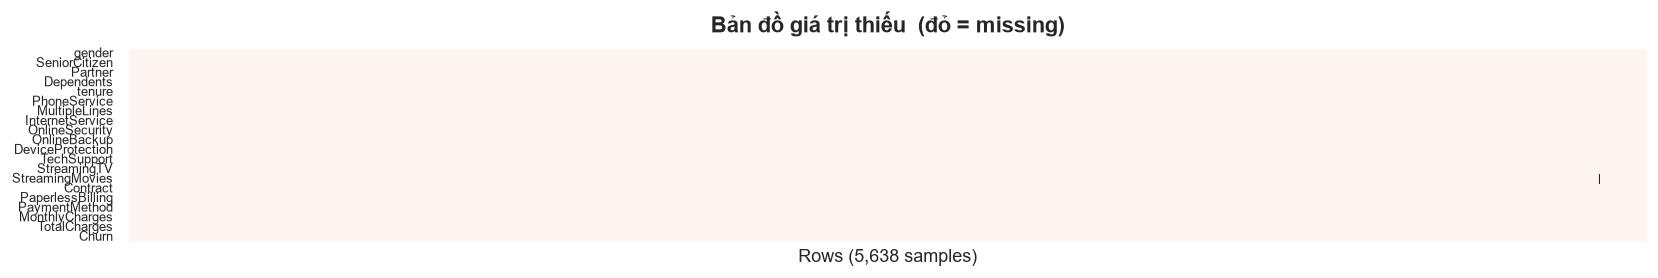

In [9]:
miss_cnt = df.isna().sum()
miss_pct = df.isna().mean() * 100

miss_df = (pd.DataFrame({'Cột': miss_cnt.index,
                          'Số dòng missing': miss_cnt.values,
                          '% missing': miss_pct.values.round(4),
                          'Kiểu': [str(df[c].dtype) for c in miss_cnt.index]})
           .query('`Số dòng missing` > 0')
           .sort_values('Số dòng missing', ascending=False))

if len(miss_df) == 0:
    print('Không có cột nào missing.')
else:
    print('Các cột có missing value:')
    display(miss_df.reset_index(drop=True))

print(f'\nTổng cột missing : {len(miss_df)}/{len(df.columns)}')
print(f'Tổng dòng missing: {df.isna().any(axis=1).sum():,}')

# --- Figure 7: Missing heatmap ---
fig, ax = plt.subplots(figsize=(14, 2.5))
sns.heatmap(df.isna().T.astype(int), cmap='Reds', cbar=False, ax=ax,
            yticklabels=df.columns, xticklabels=False, linewidths=0)
ax.set_title('Bản đồ giá trị thiếu  (đỏ = missing)', fontweight='bold', pad=10)
ax.set_xlabel(f'Rows ({len(df):,} samples)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
savefig('missing_heatmap.png')
plt.show()

## 8 — Kiểm tra Duplicate

Kiểm tra bản ghi trùng lặp: theo toàn bộ cột và riêng theo `customerID`.

In [10]:
# Cột 'customerID' đã bị drop và duplicate/customerID trùng
# đã được xử lý dứt điểm ở notebook 01_split.ipynb (bước 7 & 8),
# nên tại đây chỉ còn cần kiểm tra duplicate toàn bộ cột để xác nhận.

n_full = df.duplicated().sum()
print(f'Duplicate (toàn bộ cột)   : {n_full:,} dòng')

if n_full > 0:
    dup = df[df.duplicated(keep=False)]
    print(f'\n  -> {n_full} dòng bị trùng lặp hoàn toàn. Ví dụ 10 dòng đầu:')
    display(dup.head(10))
else:
    print('  -> Train set sạch, không có duplicate (customerID đã được xử lý ở notebook 01).')

Duplicate (toàn bộ cột)   : 23 dòng

  -> 23 dòng bị trùng lặp hoàn toàn. Ví dụ 10 dòng đầu:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
27,Female,1,No,No,7.0000,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),76.4500,503.6000,Yes
171,Female,0,No,No,1.0000,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.1000,70.1000,Yes
175,Male,0,No,No,1.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.4500,20.4500,No
178,Male,0,No,No,1.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.3000,20.3000,No
203,Female,0,No,No,72.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),20.2500,1566.9000,No
260,Male,0,Yes,Yes,46.0000,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),80.0000,3769.7000,No
348,Male,0,No,No,1.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.3000,20.3000,No
429,Female,0,No,No,1.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.9000,19.9000,No
524,Female,0,No,No,1.0000,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.2000,69.2000,Yes
687,Male,0,No,No,1.0000,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.1000,20.1000,Yes


## 9 — Phát hiện Outlier (phương pháp IQR)

Outlier: giá trị nằm ngoài `[Q1 - 1.5*IQR,  Q3 + 1.5*IQR]`.  
Chỉ phân tích trên các cột **numerical**: `tenure`, `MonthlyCharges`, `TotalCharges`.

In [11]:
def iqr_stats(series, name):
    s = series.dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((s < lo) | (s > hi)).sum()
    return {'Cột': name, 'Min': s.min(), 'Q1': Q1, 'Median': s.median(),
            'Q3': Q3, 'Max': s.max(), 'IQR': IQR,
            'Lower fence': lo, 'Upper fence': hi,
            'Số outlier': int(n_out), '% outlier': round(n_out/len(s)*100, 2)}

out_df = pd.DataFrame([iqr_stats(df[c], c) for c in numerical_cols])
print('Bảng phân tích Outlier (phương pháp IQR):')
display(out_df.set_index('Cột')
        .style.format('{:.2f}', subset=['Min','Q1','Median','Q3','Max',
                                        'IQR','Lower fence','Upper fence','% outlier'])
              .format('{:.0f}', subset=['Số outlier'])
              .highlight_between(subset=['Số outlier'], left=1, color='#FFD580'))

print('\nNhận xét:')
for _, r in out_df.iterrows():
    flag = 'CÓ outlier' if r['Số outlier'] > 0 else 'Không có'
    print(f"  {r['Cột']:20s}: {r['Số outlier']:4d} dòng ({r['% outlier']:.2f}%)  -> {flag}")

Bảng phân tích Outlier (phương pháp IQR):


,Min,Q1,Median,Q3,Max,IQR,Lower fence,Upper fence,Số outlier,% outlier
Cột,,,,,,,,,,
tenure,0.00,9.00,28.00,55.00,72.00,46.00,-60.00,124.00,0,0.00
MonthlyCharges,18.25,36.11,70.30,89.80,118.65,53.69,-44.42,170.33,0,0.00
TotalCharges,0.00,393.22,1387.72,3756.44,8670.10,3363.21,-4651.59,8801.26,0,0.00
SeniorCitizen,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,917,16.26



Nhận xét:
  tenure              :    0 dòng (0.00%)  -> Không có
  MonthlyCharges      :    0 dòng (0.00%)  -> Không có
  TotalCharges        :    0 dòng (0.00%)  -> Không có
  SeniorCitizen       :  917 dòng (16.26%)  -> CÓ outlier


## 10 — Chuẩn bị df_clean cho Visualization

Tạo `df_clean` để dùng cho các phần visualization:
- Chuẩn hóa `Churn`: `' No'` -> `'No'` (loại khoảng trắng thừa).
- Fill `TotalCharges` NaN = 0 chỉ để vẽ — **không thay đổi `df` gốc**.

In [12]:
df_clean = df.copy()
df_clean['Churn']        = df_clean['Churn'].str.strip()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print('Churn value_counts sau chuẩn hóa:')
print(df_clean['Churn'].value_counts())
avg_churn = (df_clean['Churn'] == 'Yes').mean() * 100
print(f'\nChurn rate trung bình: {avg_churn:.2f}%')

Churn value_counts sau chuẩn hóa:
Churn
No     4142
Yes    1496
Name: count, dtype: int64

Churn rate trung bình: 26.53%


## 11 — [Biểu đồ 1] Phân phối Target: Churn

Đánh giá mức độ **mất cân bằng lớp** (class imbalance).  
Quan trọng để chọn metric đánh giá (AUC, F1 thay vì Accuracy) và quyết định
có cần dùng `class_weights` hay không.

  Đã lưu: ../reports/figures/countplot_churn_target.png


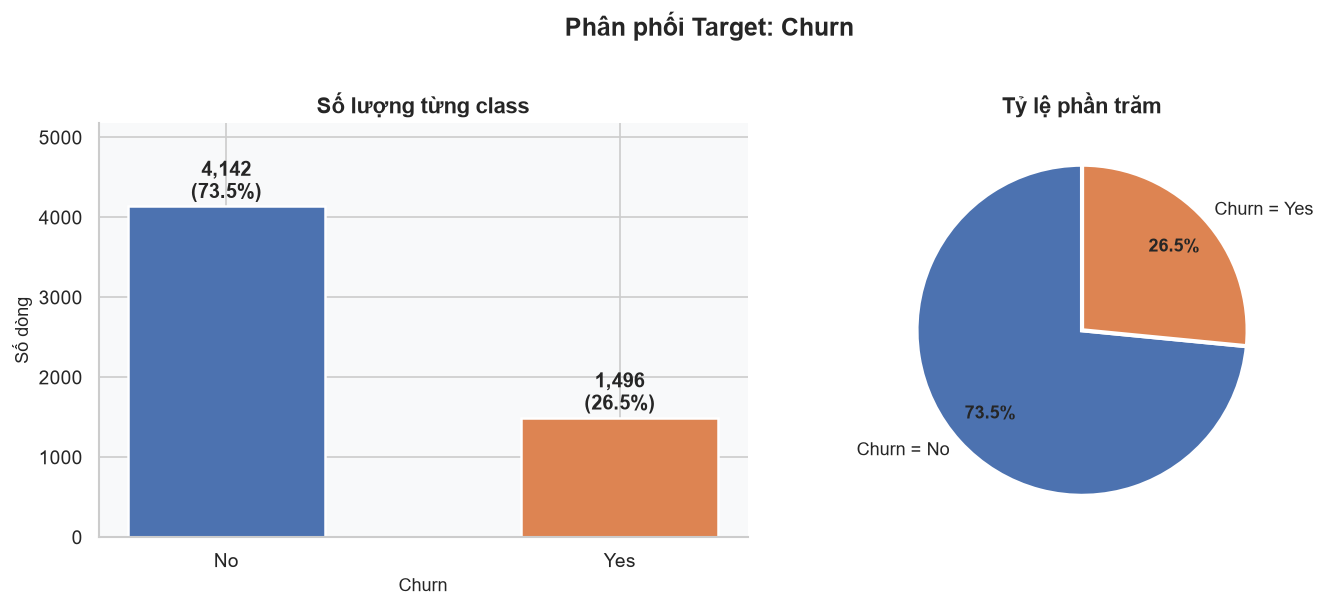

  Tỷ lệ No:Yes = 2.77:1
  -> Mất cân bằng vừa (~2-3:1). Nên dùng AUC-ROC và F1.
  -> CatBoost có scale_pos_weight / class_weights để xử lý.


In [13]:
counts = df_clean['Churn'].value_counts()
pcts   = df_clean['Churn'].value_counts(normalize=True) * 100
ORDER  = ['No', 'Yes']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Phân phối Target: Churn', fontsize=15, fontweight='bold', y=1.01)

# Bar
ax = axes[0]
bars = ax.bar(ORDER, [counts[o] for o in ORDER],
              color=[PALETTE[o] for o in ORDER],
              edgecolor='white', linewidth=1.5, width=0.5)
for bar, lbl in zip(bars, ORDER):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 30,
            f'{counts[lbl]:,}\n({pcts[lbl]:.1f}%)',
            ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(counts.values) * 1.25)
ax.set_title('Số lượng từng class', fontweight='bold')
ax.set_xlabel('Churn'); ax.set_ylabel('Số dòng')

# Pie
ax = axes[1]
wedges, texts, autotexts = ax.pie(
    [counts[o] for o in ORDER],
    labels=[f'Churn = {o}' for o in ORDER],
    colors=[PALETTE[o] for o in ORDER],
    autopct='%1.1f%%', startangle=90, pctdistance=0.75, labeldistance=1.08,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5},
    textprops={'fontsize': 11},
)
for at in autotexts: at.set_fontweight('bold')
ax.set_title('Tỷ lệ phần trăm', fontweight='bold')

plt.tight_layout()
savefig('countplot_churn_target.png')
plt.show()

ratio = counts['No'] / counts['Yes']
print(f'  Tỷ lệ No:Yes = {ratio:.2f}:1')
print('  -> Mất cân bằng vừa (~2-3:1). Nên dùng AUC-ROC và F1.')
print('  -> CatBoost có scale_pos_weight / class_weights để xử lý.')

## 12 — [Biểu đồ 2] Phân phối Numerical (Histogram + KDE)

Histogram + KDE phân tách theo `Churn` giúp thấy:
- Phân phối tổng thể (có lệch không?)
- Sự khác biệt giữa nhóm churned vs retained

**Skewness:** `|skew| < 0.5` gần đối xứng, `>= 1` lệch mạnh.

  Đã lưu: ../reports/figures/hist_numerical.png


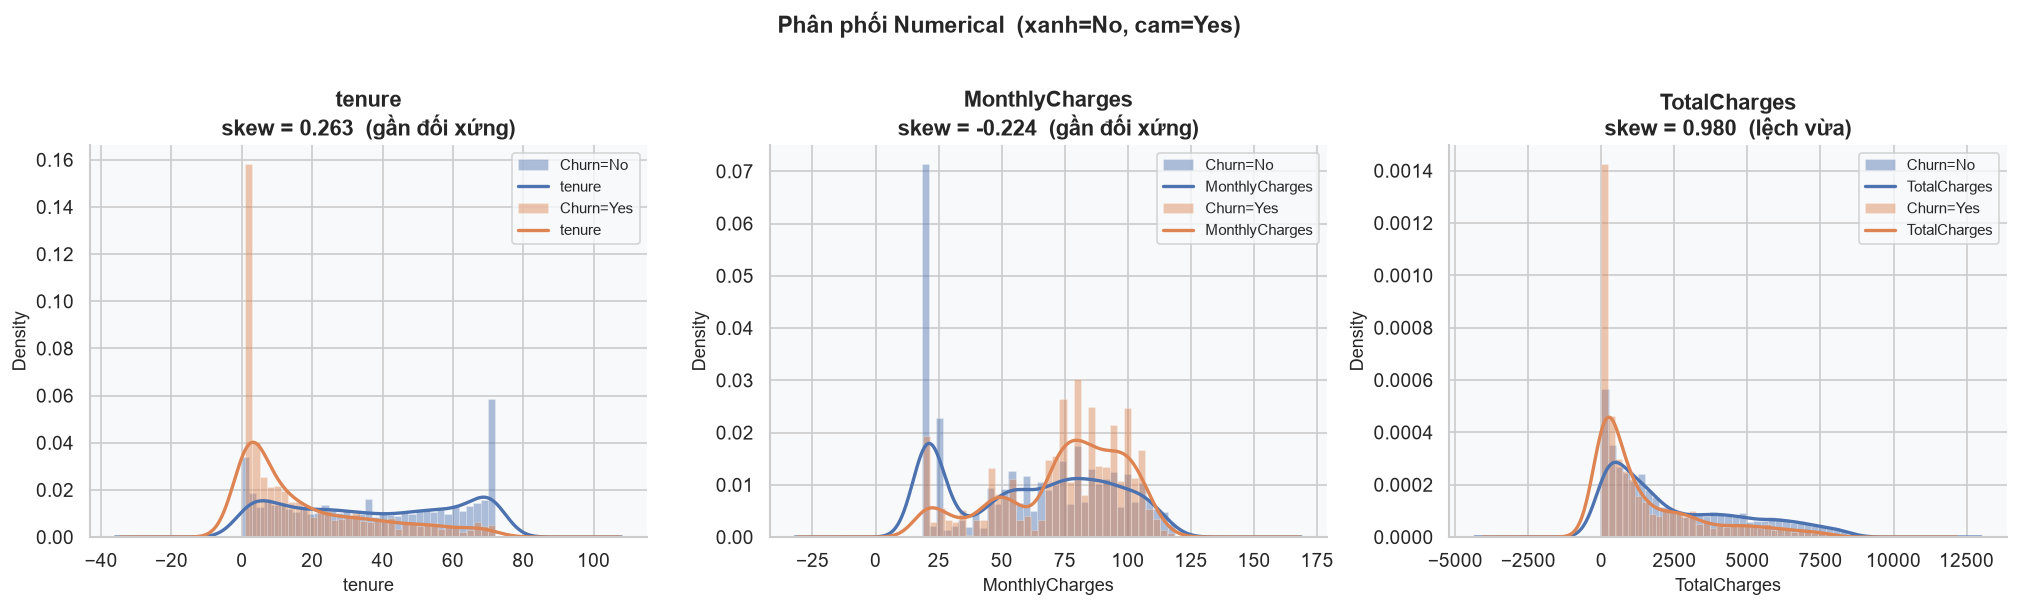

Skewness:
  tenure              : skew = +0.2630  (gần đối xứng)
  MonthlyCharges      : skew = -0.2244  (gần đối xứng)
  TotalCharges        : skew = +0.9795  (lệch vừa)
  SeniorCitizen       : skew = +1.8288  (lệch mạnh)


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Phân phối Numerical  (xanh=No, cam=Yes)',
             fontsize=14, fontweight='bold', y=1.01)

for ax, col in zip(axes, numerical_cols):
    for churn_val in ['No', 'Yes']:
        grp = df_clean[df_clean['Churn'] == churn_val][col]
        ax.hist(grp, bins=35, alpha=0.45, color=PALETTE[churn_val],
                label=f'Churn={churn_val}', density=True,
                edgecolor='white', linewidth=0.3)
        grp.plot.kde(ax=ax, color=PALETTE[churn_val], lw=2)
    s = df_clean[col].skew()
    skew_lbl = 'gần đối xứng' if abs(s)<0.5 else ('lệch vừa' if abs(s)<1 else 'lệch mạnh')
    ax.set_title(f'{col}\nskew = {s:.3f}  ({skew_lbl})', fontweight='bold')
    ax.set_xlabel(col); ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.tight_layout()
savefig('hist_numerical.png')
plt.show()

print('Skewness:')
for col in numerical_cols:
    s = df_clean[col].skew()
    lbl = 'gần đối xứng' if abs(s)<0.5 else ('lệch vừa' if abs(s)<1 else 'lệch mạnh')
    print(f'  {col:20s}: skew = {s:+.4f}  ({lbl})')

## 13 — [Biểu đồ 3] Boxplot Numerical (Trực quan hóa Outlier)

Boxplot minh họa Q1, median, Q3, whisker và outlier.  
Phân tách theo `Churn` để so sánh phân phối giữa 2 nhóm.

  Đã lưu: ../reports/figures/boxplot_numerical.png


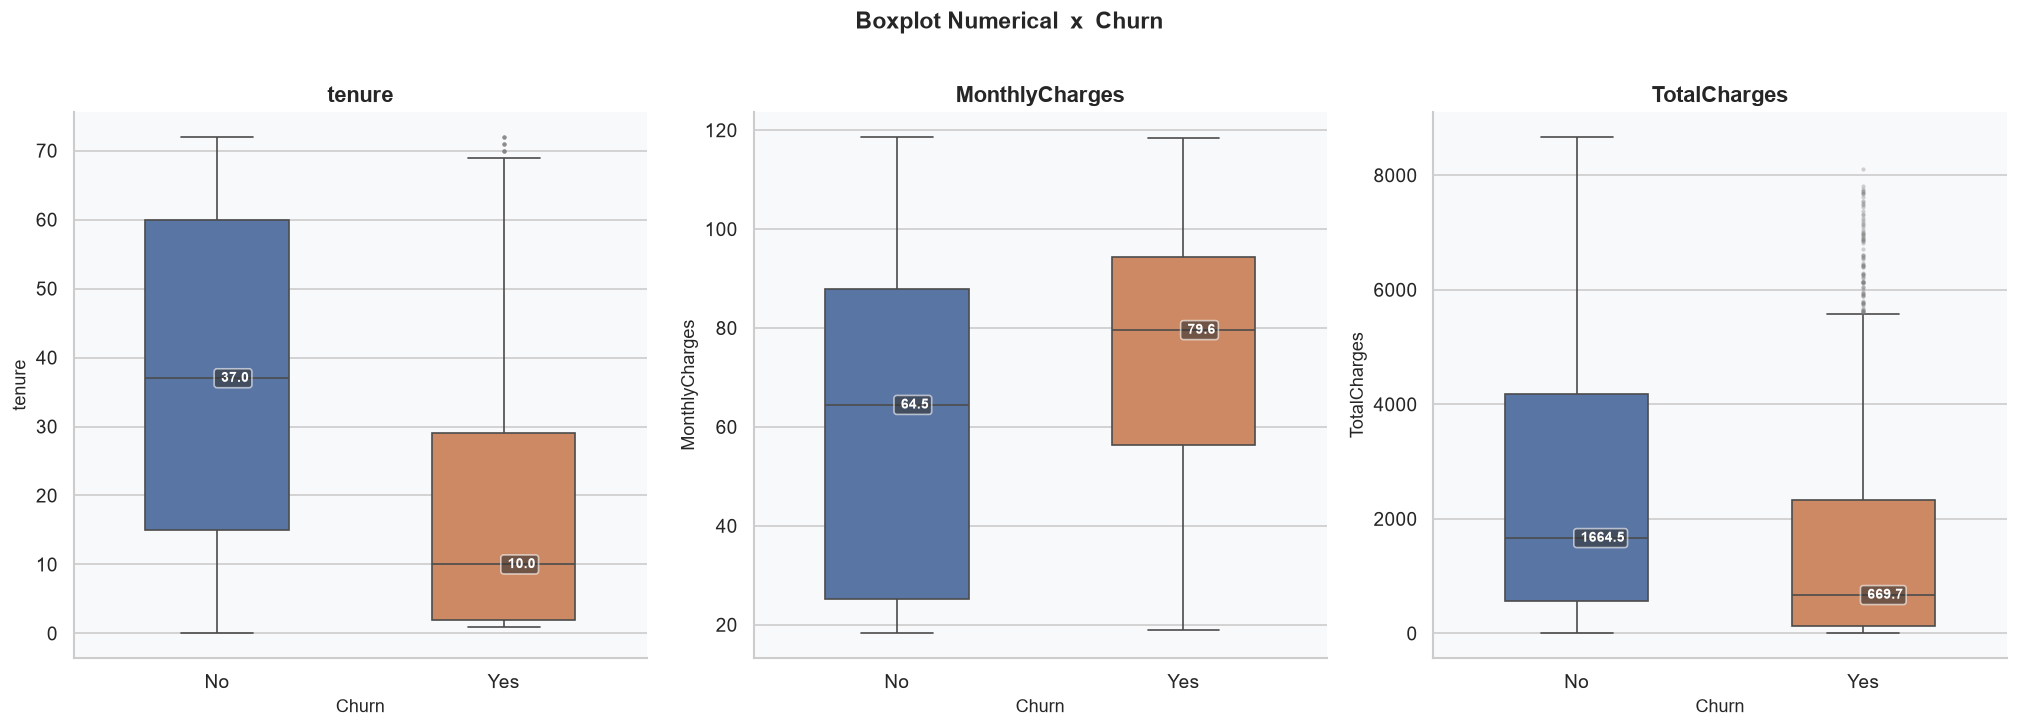

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.suptitle('Boxplot Numerical  x  Churn', fontsize=14, fontweight='bold', y=1.01)

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(
        data=df_clean, x='Churn', y=col, palette=PALETTE,
        order=['No', 'Yes'], width=0.5,
        flierprops=dict(marker='o', markerfacecolor='gray',
                        markersize=2.5, alpha=0.35, markeredgewidth=0),
        ax=ax,
    )
    for i, cv in enumerate(['No', 'Yes']):
        med = df_clean[df_clean['Churn'] == cv][col].median()
        ax.text(i, med, f' {med:.1f}', va='center', fontsize=8.5, fontweight='bold',
                color='white', bbox=dict(boxstyle='round,pad=0.2',
                                         facecolor='#333', alpha=0.6))
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Churn'); ax.set_ylabel(col)

plt.tight_layout()
savefig('boxplot_numerical.png')
plt.show()

## 14 — [Biểu đồ 4] Ma trận tương quan (Correlation Matrix)

Tính ma trận tương quan Pearson trên các cột numerical + Churn (encoded).  
Phát hiện **đa cộng tuyến** (|r| > 0.8) và feature nào liên quan nhất đến target.

  Đã lưu: ../reports/figures/heatmap_correlation.png


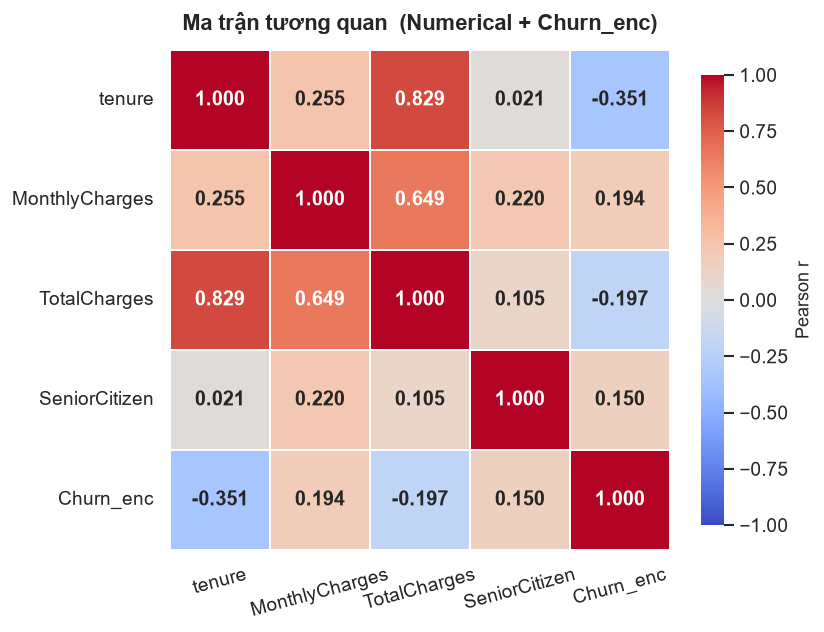

Tương quan với Churn (|r| giảm dần):
  tenure              : r = -0.3511  (âm (-)   , vừa)
  TotalCharges        : r = -0.1974  (âm (-)   , yếu)
  MonthlyCharges      : r = +0.1944  (dương (+), yếu)
  SeniorCitizen       : r = +0.1499  (dương (+), yếu)


In [16]:
df_corr = df_clean[numerical_cols].copy()
df_corr['Churn_enc'] = (df_clean['Churn'] == 'Yes').astype(int)
corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    corr, annot=True, fmt='.3f',
    cmap='coolwarm', vmin=-1, vmax=1,
    linewidths=1, linecolor='white',
    square=True, ax=ax,
    cbar_kws={'shrink': 0.75, 'label': 'Pearson r'},
    annot_kws={'size': 12, 'weight': 'bold'},
)
ax.set_title('Ma trận tương quan  (Numerical + Churn_enc)',
             fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=15)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
savefig('heatmap_correlation.png')
plt.show()

print('Tương quan với Churn (|r| giảm dần):')
cc = corr['Churn_enc'].drop('Churn_enc').sort_values(key=abs, ascending=False)
for feat, r in cc.items():
    d = 'dương (+)' if r > 0 else 'âm (-)   '
    s = 'mạnh' if abs(r) > 0.4 else ('vừa' if abs(r) > 0.2 else 'yếu')
    print(f'  {feat:20s}: r = {r:+.4f}  ({d}, {s})')

## 15 — [Biểu đồ 5] Churn Rate theo từng Categorical Feature

Stacked bar chart thể hiện **tỷ lệ Churn=Yes** trong từng nhóm giá trị.  
Đường kẻ ngang xám = Churn rate trung bình toàn dataset.  
Cột nào có churn rate chênh lệch nhiều giữa các nhóm -> **predictive power cao**.

  Đã lưu: ../reports/figures/churn_rate_by_categorical.png


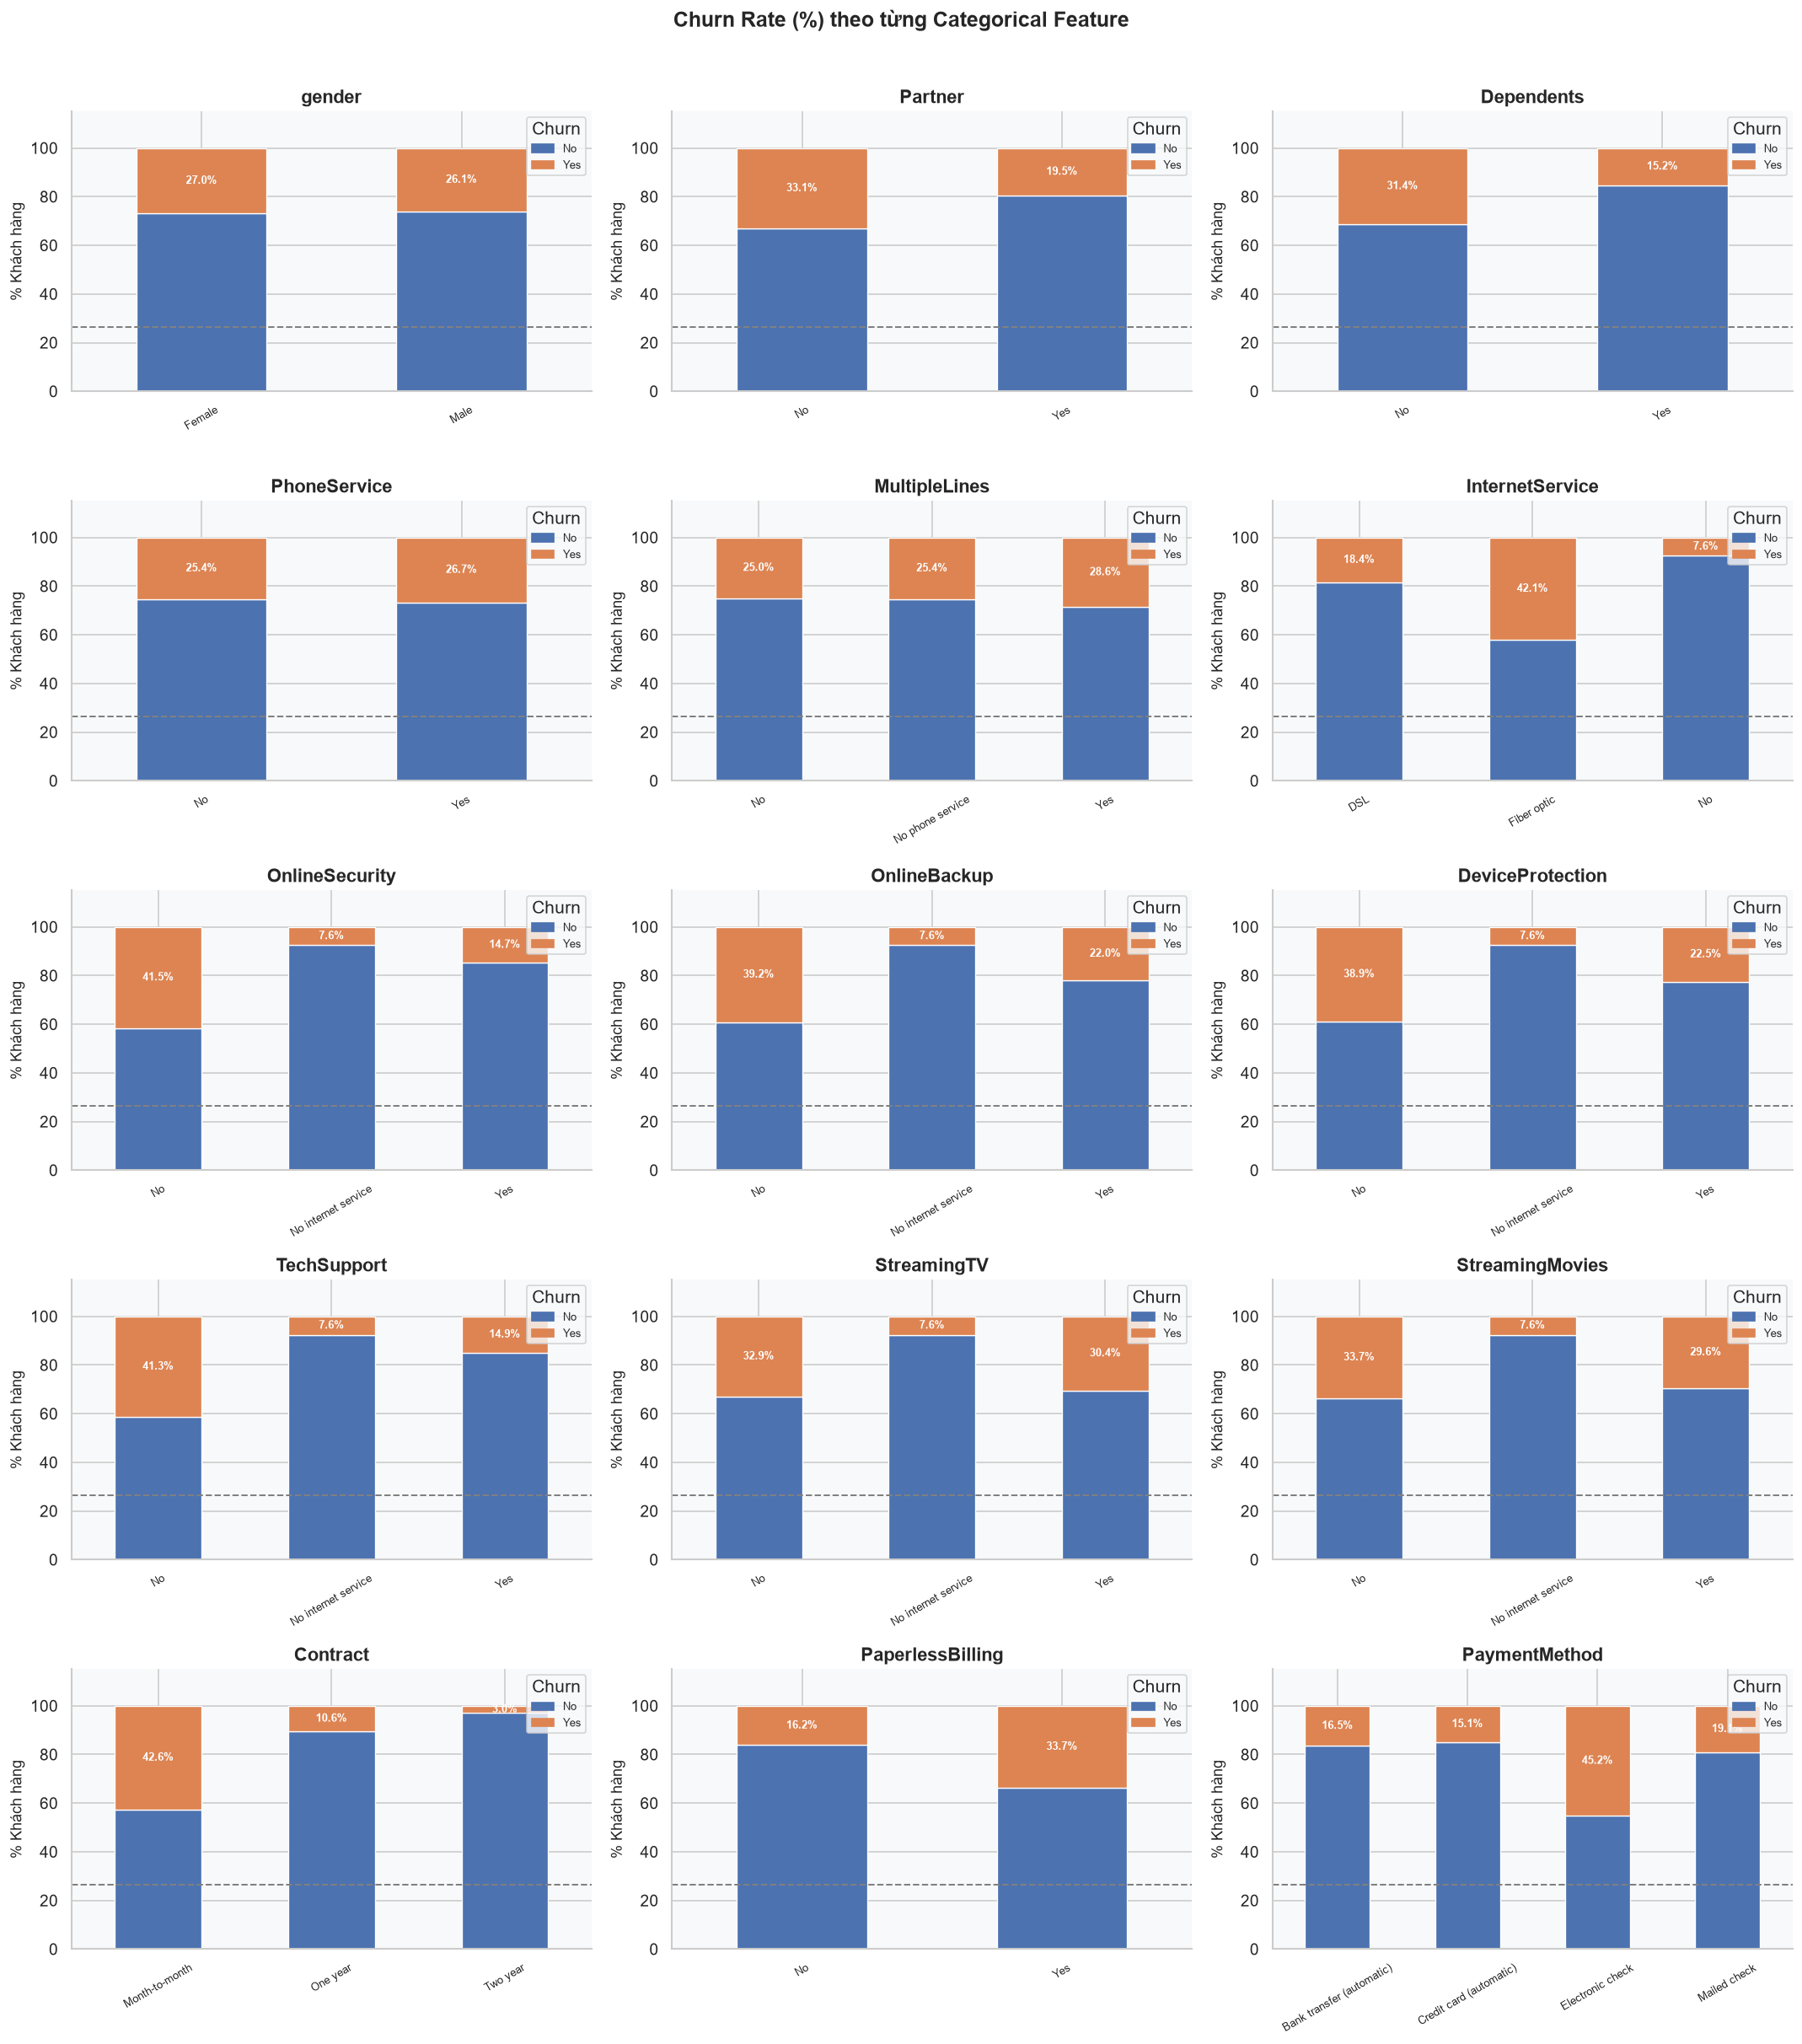

In [17]:
plot_cat_cols = [c for c in categorical_cols if df_clean[c].nunique() <= 10]
n_cols = 3
n_rows = (len(plot_cat_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle('Churn Rate (%) theo từng Categorical Feature',
             fontsize=15, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(plot_cat_cols):
    ax = axes[i]
    ct = df_clean.groupby([col, 'Churn']).size().unstack(fill_value=0)
    for v in ['No', 'Yes']:
        if v not in ct.columns: ct[v] = 0
    ct_pct = ct[['No','Yes']].div(ct[['No','Yes']].sum(axis=1), axis=0) * 100

    ct_pct.plot(kind='bar', stacked=True, ax=ax,
                color=[PALETTE['No'], PALETTE['Yes']],
                edgecolor='white', linewidth=0.8, legend=False)

    for j, (_, row) in enumerate(ct_pct.iterrows()):
        if row['Yes'] > 3:
            ax.text(j, row['No'] + row['Yes']/2,
                    f"{row['Yes']:.1f}%",
                    ha='center', va='center', fontsize=8, fontweight='bold', color='white')

    ax.axhline(avg_churn, color='gray', ls='--', lw=1.2,
               label=f'Avg {avg_churn:.1f}%')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('% Khách hàng')
    ax.set_ylim(0, 115)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend(handles=[
        plt.Rectangle((0,0),1,1, color=PALETTE['No'], label='No'),
        plt.Rectangle((0,0),1,1, color=PALETTE['Yes'], label='Yes'),
    ], title='Churn', loc='upper right', fontsize=8)

for j in range(len(plot_cat_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
savefig('churn_rate_by_categorical.png')
plt.show()

## 16 — [Biểu đồ 6] Phân phối giá trị Categorical

Số lượng mẫu trong từng nhóm, tô màu theo Churn.  
Phát hiện **mất cân bằng trong feature** (nhóm nào quá ít mẫu?)
và phát hiện **dirty data** (giá trị viết khác nhau cùng một ý nghĩa).

  Đã lưu: ../reports/figures/countplot_categorical.png


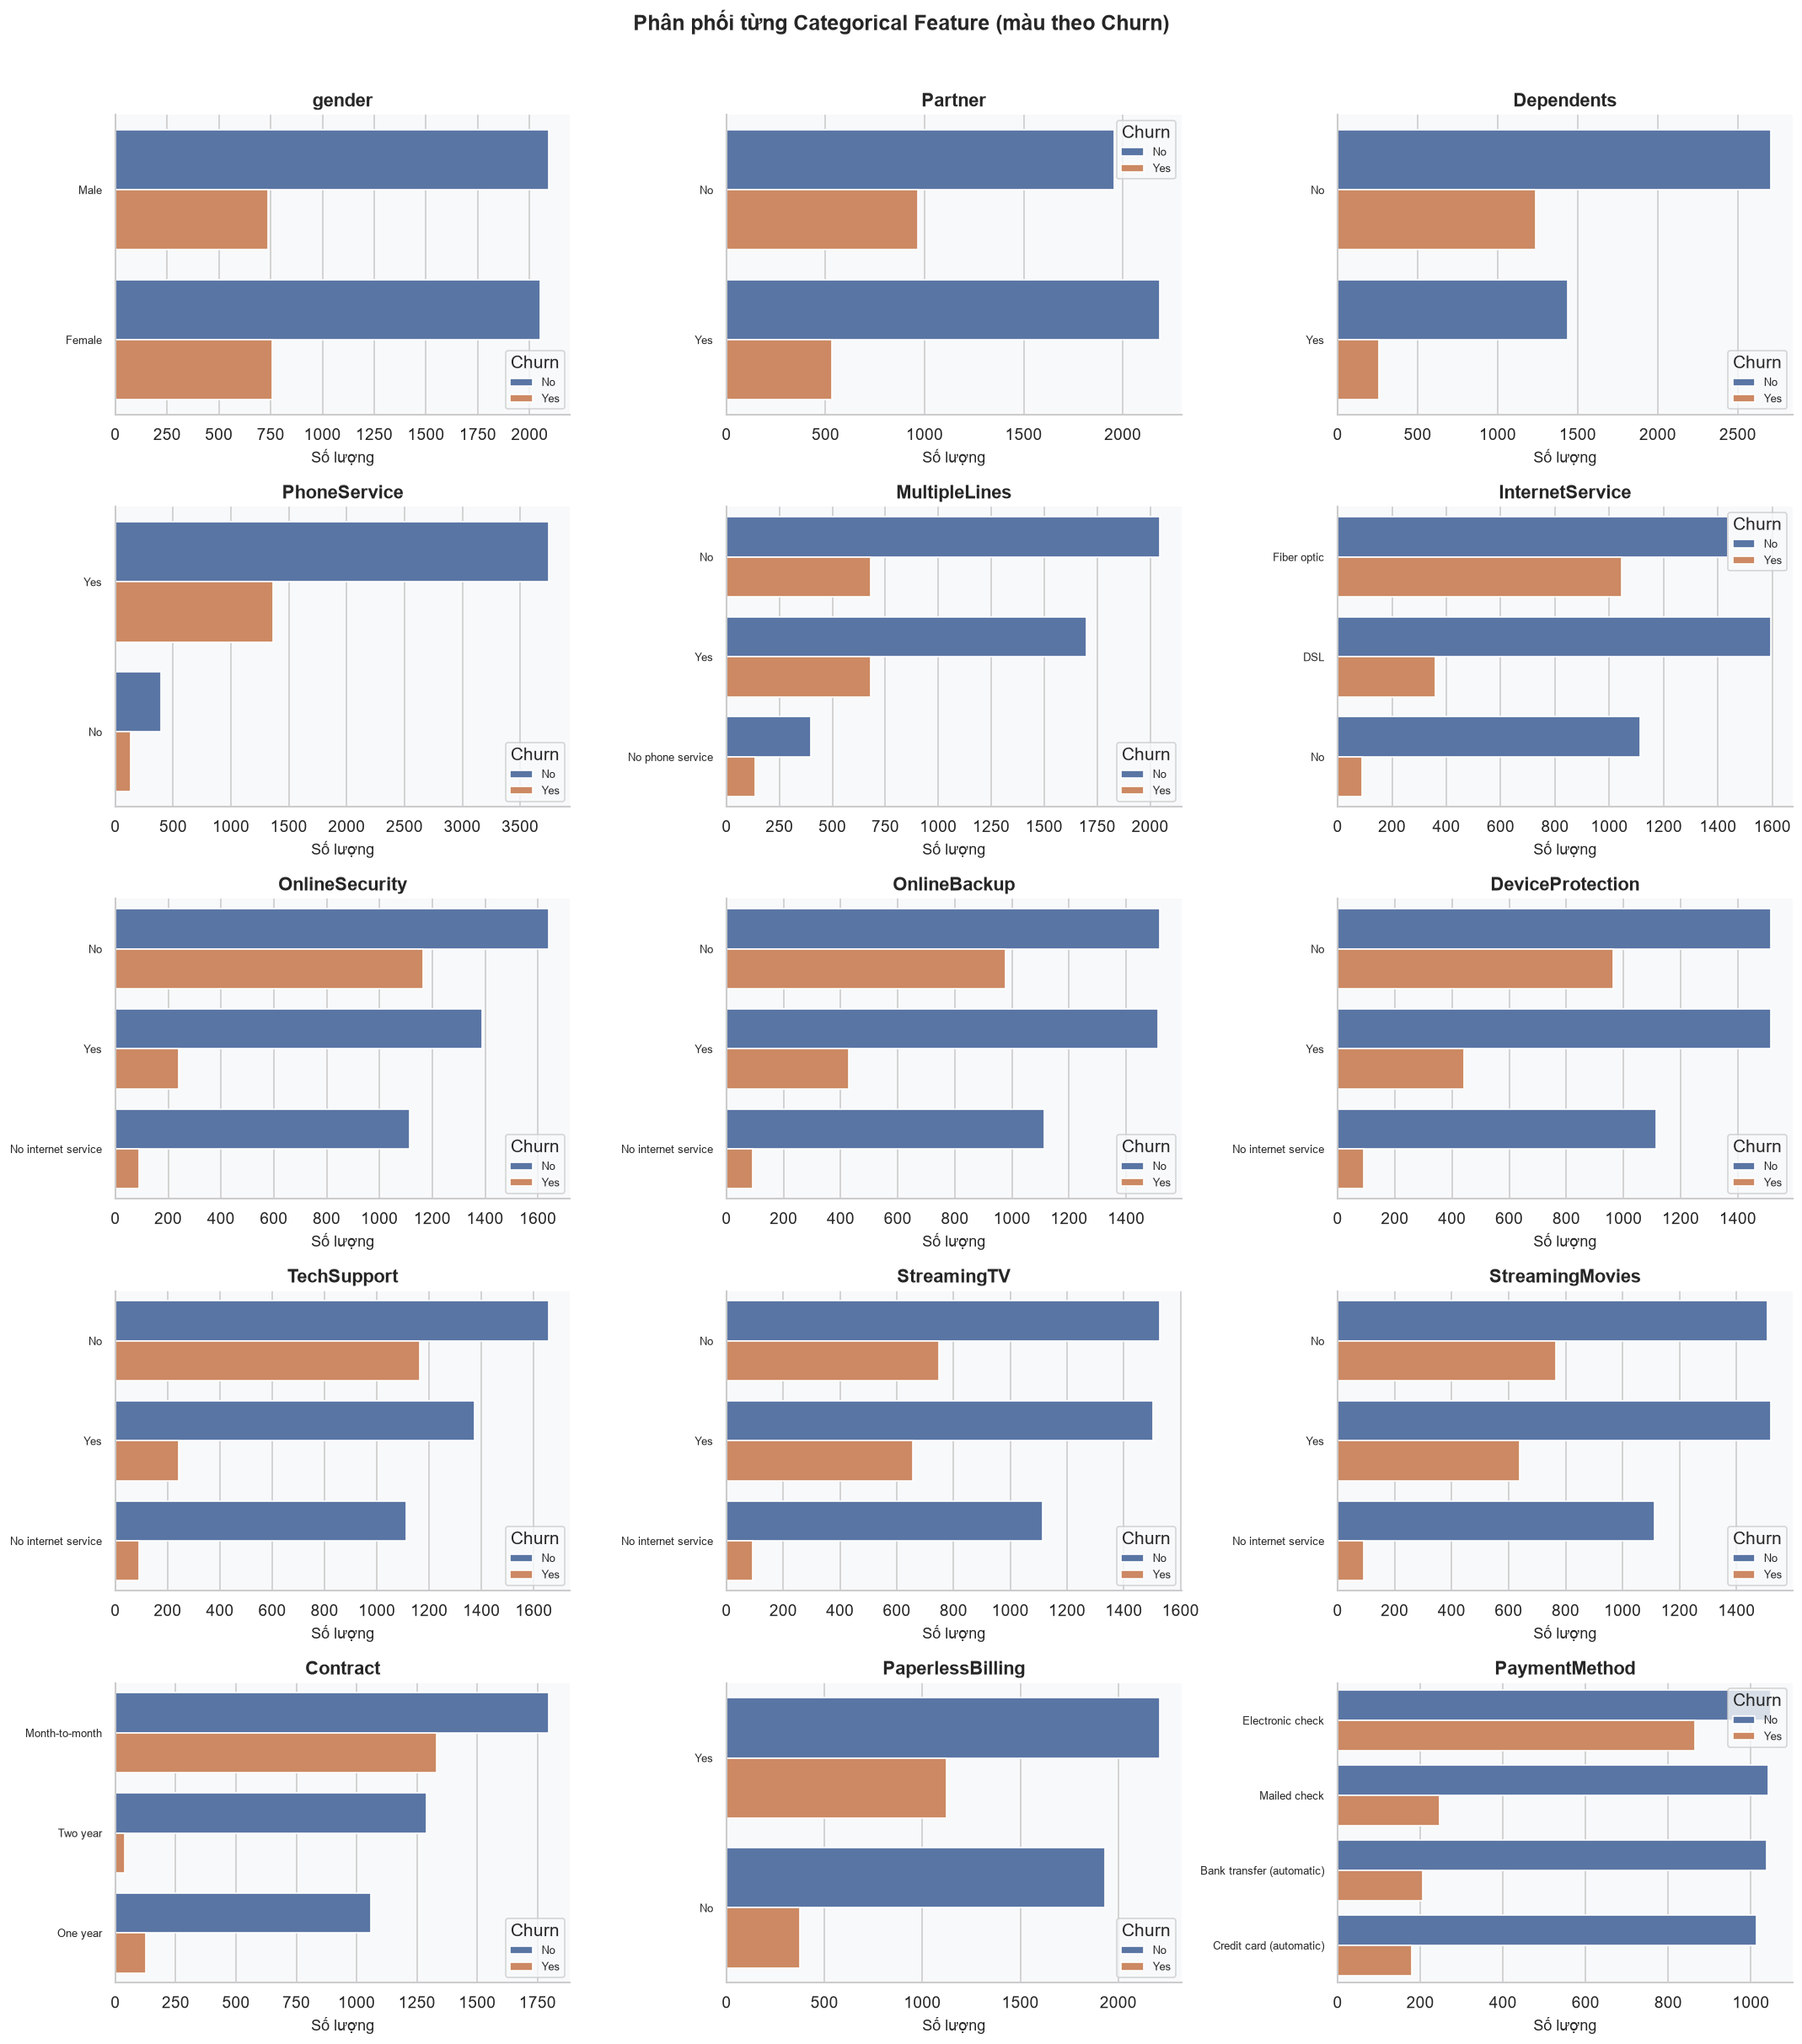

In [18]:
n_cols = 3
n_rows = (len(plot_cat_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle('Phân phối từng Categorical Feature (màu theo Churn)',
             fontsize=15, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(plot_cat_cols):
    ax = axes[i]
    sns.countplot(
        data=df_clean, y=col,
        hue='Churn', hue_order=['No', 'Yes'],
        palette=PALETTE,
        order=df_clean[col].value_counts().index,
        ax=ax,
    )
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Số lượng')
    ax.set_ylabel('')
    ax.legend(title='Churn', fontsize=8)
    ax.tick_params(axis='y', labelsize=8)

for j in range(len(plot_cat_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
savefig('countplot_categorical.png')
plt.show()

## 17 — [Biểu đồ 8] InternetService x Sub-Services (Feature Interaction)

Nhiều cột dịch vụ (OnlineSecurity, TechSupport...) phụ thuộc vào `InternetService`.  
Heatmap churn rate giúp phát hiện **tổ hợp có rủi ro cao nhất**.

  Đã lưu: ../reports/figures/heatmap_internetservice_subservices.png


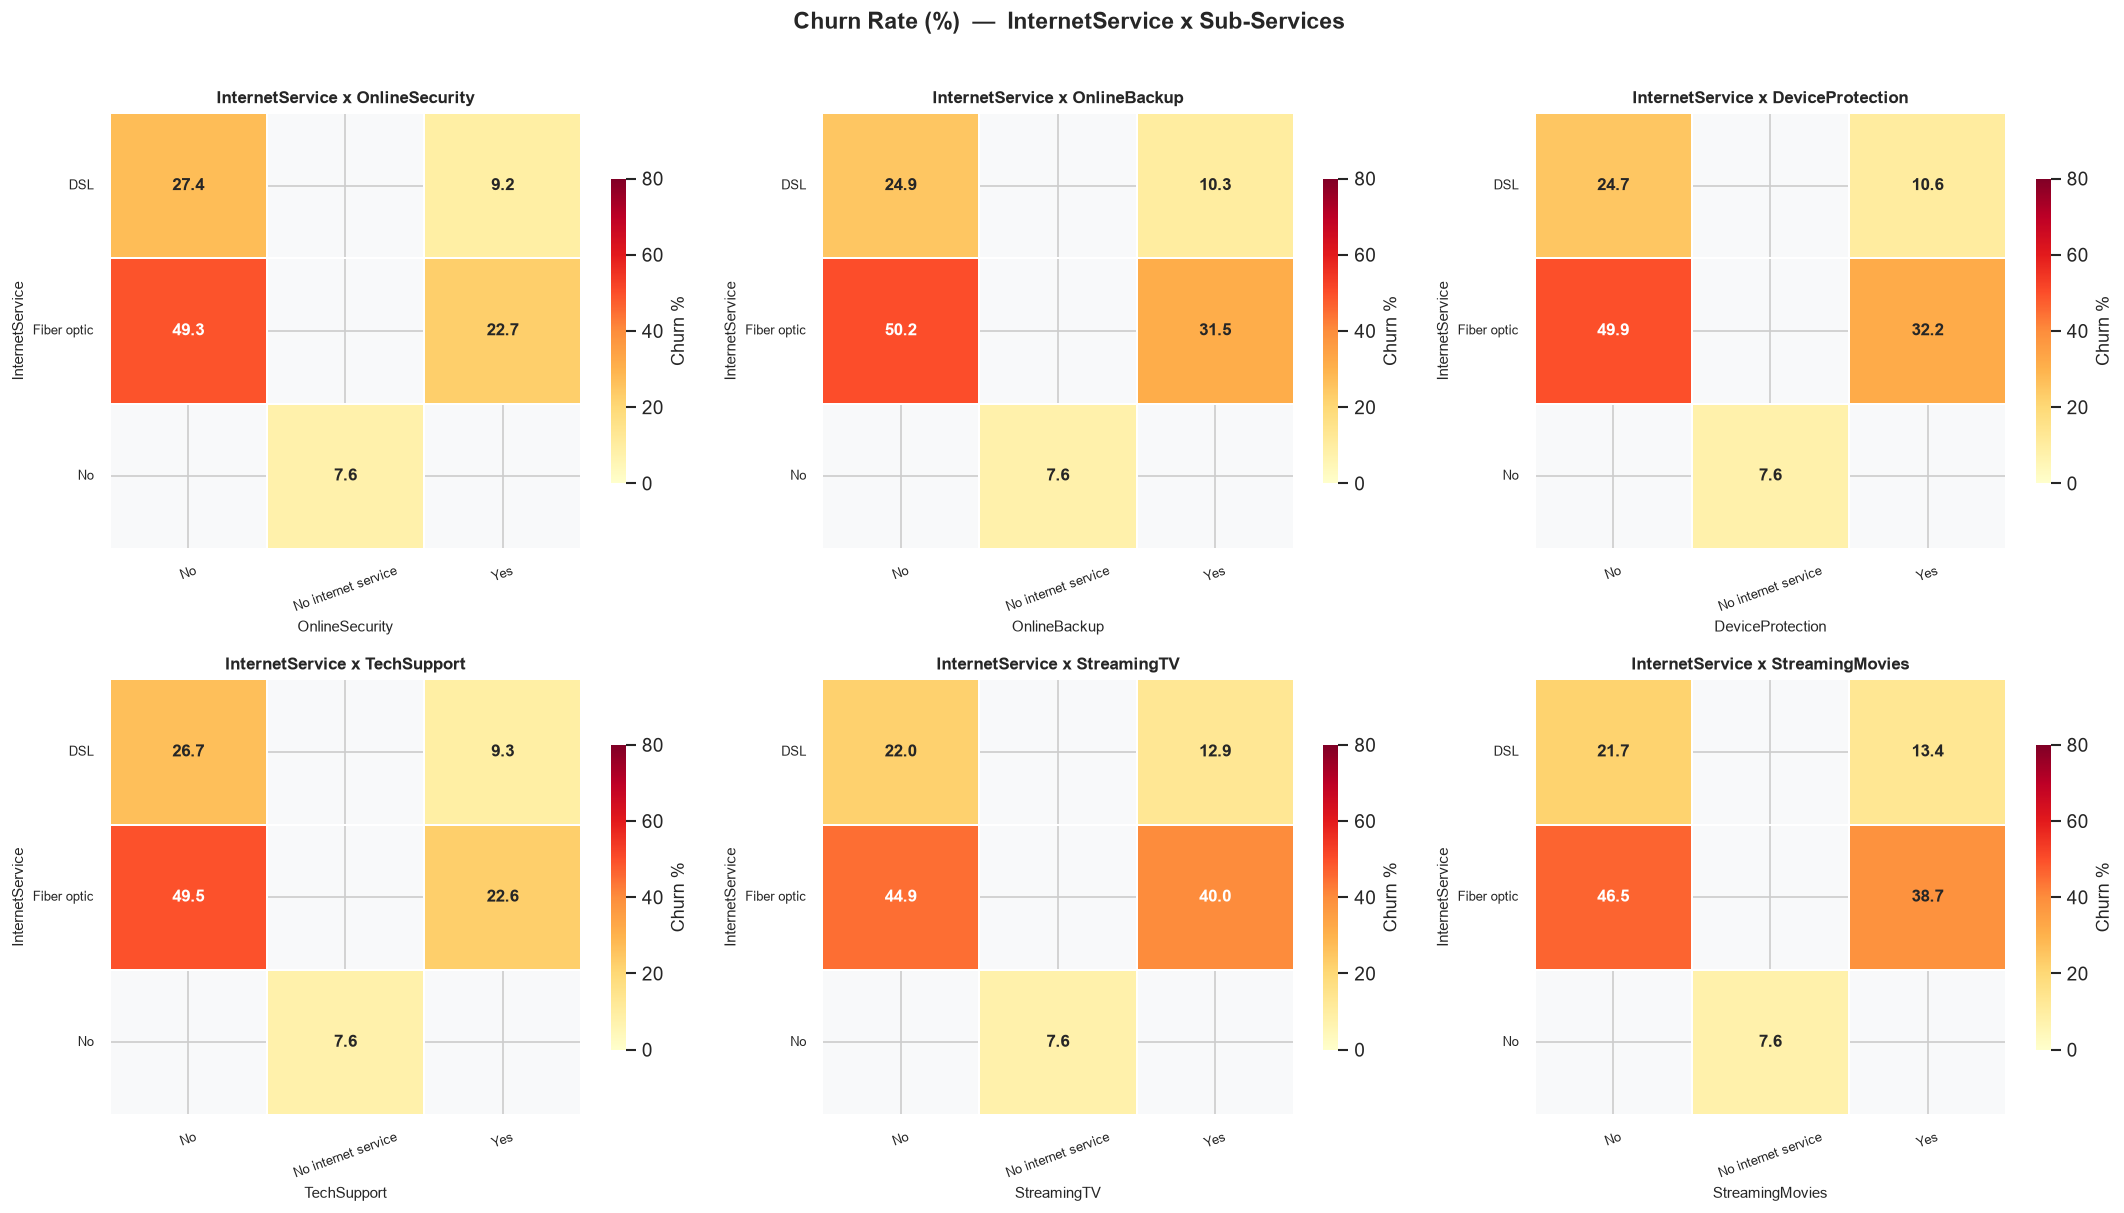

In [19]:
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Churn Rate (%)  —  InternetService x Sub-Services',
             fontsize=14, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(service_cols):
    ax = axes[i]
    tmp = (df_clean.groupby(['InternetService', col])['Churn']
           .apply(lambda x: (x == 'Yes').mean() * 100)
           .reset_index(name='ChurnRate'))
    pivot = tmp.pivot(index='InternetService', columns=col, values='ChurnRate')

    sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
                vmin=0, vmax=80, ax=ax,
                linewidths=1, linecolor='white',
                cbar_kws={'label': 'Churn %', 'shrink': 0.7},
                annot_kws={'size': 10, 'weight': 'bold'})
    ax.set_title(f'InternetService x {col}', fontweight='bold', fontsize=10)
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel('InternetService', fontsize=9)
    ax.tick_params(axis='x', rotation=20, labelsize=8)
    ax.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
savefig('heatmap_internetservice_subservices.png')
plt.show()

## 18 — [Biểu đồ 9] Scatter: tenure x MonthlyCharges

Scatter 2D phân tách theo Churn giúp thấy **vùng quyết định** của model:  
- Tenure thấp + MonthlyCharges cao -> xu hướng Churn cao.
- Tenure cao -> khách hàng trưởng thành, ít Churn hơn.

  Đã lưu: ../reports/figures/scatter_tenure_charges.png


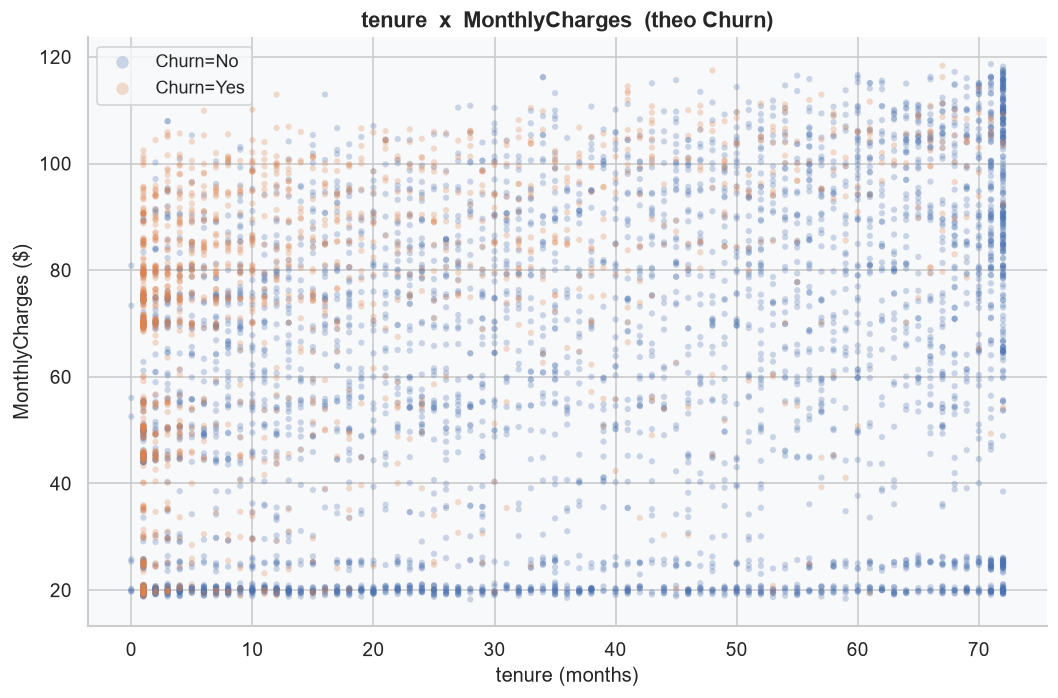

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

# Vẽ No trước để Yes hiện lên trên
for churn_val in ['No', 'Yes']:
    sub = df_clean[df_clean['Churn'] == churn_val]
    ax.scatter(sub['tenure'], sub['MonthlyCharges'],
               c=PALETTE[churn_val], alpha=0.28, s=14,
               label=f'Churn={churn_val}', edgecolors='none')

ax.set_xlabel('tenure (months)', fontsize=12)
ax.set_ylabel('MonthlyCharges ($)', fontsize=12)
ax.set_title('tenure  x  MonthlyCharges  (theo Churn)',
             fontweight='bold', fontsize=13)
ax.legend(fontsize=11, markerscale=2)
plt.tight_layout()
savefig('scatter_tenure_charges.png')
plt.show()

## 19 — [Biểu đồ 10] Phân tích Tenure Group

Chia `tenure` thành các nhóm để thấy rõ **giai đoạn nào khách hàng dễ rời nhất**.  
Chỉ sử dụng giá trị tenure hợp lệ (0..72 tháng).

  Đã lưu: ../reports/figures/tenure_group_analysis.png


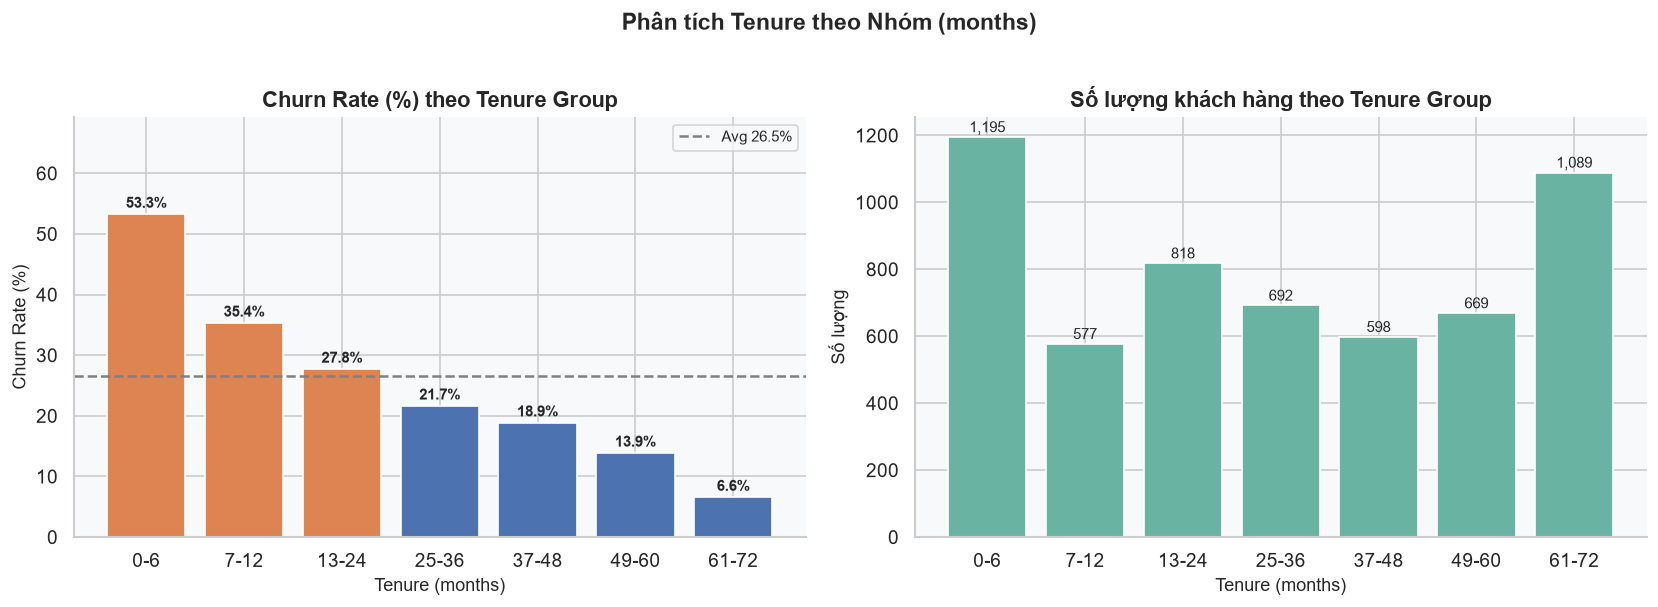

In [21]:
df_t = df_clean[df_clean['tenure'].between(0, 72)].copy()
bins   = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ['0-6', '7-12', '13-24', '25-36', '37-48', '49-60', '61-72']
df_t['tenure_group'] = pd.cut(df_t['tenure'], bins=bins,
                               labels=labels, include_lowest=True)

tg = (df_t.groupby('tenure_group', observed=False)['Churn']
      .apply(lambda x: (x=='Yes').mean() * 100)
      .reset_index(name='ChurnRate'))
cnt = df_t.groupby('tenure_group', observed=False).size().reset_index(name='Count')
tg  = tg.merge(cnt, on='tenure_group')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Phân tích Tenure theo Nhóm (months)', fontsize=14,
             fontweight='bold', y=1.01)

# Plot 1: Churn rate
ax = axes[0]
bar_c = ['#DD8452' if r > avg_churn else '#4C72B0' for r in tg['ChurnRate']]
bars  = ax.bar(tg['tenure_group'].astype(str), tg['ChurnRate'],
               color=bar_c, edgecolor='white', linewidth=1)
ax.axhline(avg_churn, color='gray', ls='--', lw=1.5,
           label=f'Avg {avg_churn:.1f}%')
for bar, val in zip(bars, tg['ChurnRate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(0, tg['ChurnRate'].max() * 1.3)
ax.set_title('Churn Rate (%) theo Tenure Group', fontweight='bold')
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Churn Rate (%)')
ax.legend(fontsize=9)

# Plot 2: Số lượng khách hàng
ax = axes[1]
ax.bar(tg['tenure_group'].astype(str), tg['Count'],
       color='#69B3A2', edgecolor='white', linewidth=1)
for bar, val in zip(ax.patches, tg['Count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f'{val:,}', ha='center', va='bottom', fontsize=9)
ax.set_title('Số lượng khách hàng theo Tenure Group', fontweight='bold')
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Số lượng')

plt.tight_layout()
savefig('tenure_group_analysis.png')
plt.show()

In [22]:
out_df_lookup = out_df.set_index('Cột')

print(f"Cột numerical  : {len(numerical_cols)} cột -> {numerical_cols}")
print(f"Cột categorical: {len(categorical_cols)} cột")
print(f"Outlier MonthlyCharges: {out_df_lookup.loc['MonthlyCharges','Số outlier']} dòng, "
      f"giá trị hợp lệ trong khoảng [{df['MonthlyCharges'].min():.2f}, "
      f"{df['MonthlyCharges'].max():.2f}]")
print(f"Outlier tenure: {out_df_lookup.loc['tenure','Số outlier']} dòng, "
      f"giá trị hợp lệ trong khoảng [{df['tenure'].min():.0f}, "
      f"{df['tenure'].max():.0f}]")

Cột numerical  : 4 cột -> ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Cột categorical: 15 cột
Outlier MonthlyCharges: 0 dòng, giá trị hợp lệ trong khoảng [18.25, 118.65]
Outlier tenure: 0 dòng, giá trị hợp lệ trong khoảng [0, 72]


---
## 20 — Tổng kết: Dataset có phù hợp CatBoost không?

### Bảng tổng kết phát hiện từ EDA

*(Số liệu tính trực tiếp từ DataFrame đang chạy trong notebook này — xem cell ngay trên.)*

| Tiêu chí | Phát hiện | Đánh giá |
|---|---|---|
| **Cột numerical** | 4 cột (`tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen`) | Ít -> không cần scale phức tạp |
| **Cột categorical** | 15 cột | Nhiều -> **CatBoost có lợi thế lớn** |
| **Chất lượng dữ liệu** | Đã chuẩn hóa nhãn/giá trị phi lý ở `01_split.ipynb` (`clean_target_column` + `clean_raw_data` + `resolve_duplicate_customer_ids`) | Sanity check ở mục 6 không còn phát hiện giá trị bất thường nào |
| **Missing values** | `StreamingTV` 1 dòng (0.02%); các cột khác 0 dòng | Rất ít, impute đơn giản |
| **Outlier (IQR)** | `MonthlyCharges`: 0 dòng, hợp lệ trong [18.25, 118.65]; `tenure`: 0 dòng, hợp lệ trong [0, 72] | Đã được chặn ở `_invalidate_impossible_numeric_values` trong `clean_raw_data` |
| **Mất cân bằng lớp** | ~73.5% No / ~26.5% Yes (~2.77:1) | Vừa -> dùng AUC/F1; xem xét class_weight |
| **Đa cộng tuyến** | `tenure` <-> `TotalCharges` tương quan cao (~0.83) | Tree-based model tự xử lý được |
| **Predictive features** | `Contract`, `InternetService`, `OnlineSecurity`, tenure ngắn | Feature quan trọng nhất |

> Lưu ý: `SeniorCitizen` (biến nhị phân 0/1) cũng nằm trong `numerical_cols` nên cũng
> được IQR quét qua ở mục 9 và bị báo "outlier" ~16% — đây là **false positive** của
> phương pháp IQR khi áp dụng lên biến nhị phân, không phải lỗi dữ liệu.

### Kết luận

**Dataset này rất phù hợp để áp dụng CatBoost**, cụ thể vì:

1. **Nhiều categorical feature (15 cột, sau khi bỏ `customerID` và tách `SeniorCitizen`
   sang numerical):** CatBoost xử lý bằng Ordered Target Statistics, tránh target
   leakage mà one-hot / label encoding thường mắc phải.

2. **Dữ liệu đã được chuẩn hóa từ `01_split.ipynb`:** Nhãn Churn/gender/SeniorCitizen,
   giá trị phi lý (tenure/MonthlyCharges/TotalCharges) và customerID trùng dữ liệu khác
   nhau đã được xử lý dứt điểm trước khi đến EDA — không còn thuộc phạm vi
   Feature Engineering nữa.

3. **Outlier không còn xuất hiện ở các cột đã invalidate:** `_invalidate_impossible_
   numeric_values` trong `clean_raw_data` đã chặn giá trị phi lý nghiệp vụ (vd.
   MonthlyCharges > 150, tenure < 0 hoặc > 100) trước khi đến EDA — phương pháp IQR ở
   mục 9 xác nhận lại: 0 outlier ở cả `tenure` và `MonthlyCharges`.

4. **Mất cân bằng lớp vừa (~2.7:1):** Không quá cực đoan. Theo dõi bằng AUC-ROC và F1.

5. **Đa cộng tuyến:** Không ảnh hưởng tree-based model.

---
*Bước tiếp theo: `03_feature_engineering.ipynb` — tạo thêm feature nghiệp vụ
(tenure_group, num_addon_services, avg_monthly_spend), fit tiền xử lý thống kê
(median fill + Target Statistics) và encode categorical.*